# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: 'Even if the models end up having a substantially different appearance, the predictions they generate are often very similar.'

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Kim, Graham Evans, Sid Luthra

**Date:** 11/16/26

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

In [13]:
# q1
df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')
df.columns = df.columns.str.strip().str.lower()

print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())

y = df['death_event'].astype(int)
X = df.drop(columns=['death_event', 'time'])
print(y.value_counts().sort_index())

Shape: (299, 13)
Missing values: 0
Exact duplicate rows: 0
death_event
0    203
1     96
Name: count, dtype: int64


In [14]:
# q2
baseline_seed = 42
other_seeds = [7, 19, 73, 101]

def fit_split(seed):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)

    models = {
        "Tree": DecisionTreeClassifier(
            max_depth=3, min_samples_leaf=10, random_state=0
        ),
        "Logistic": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000)
        ),
    }

    predictions = pd.DataFrame(index=X_test.index)
    scores = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name] = model.predict_proba(X_test)[:, 1]

        scores.append({
            "seed": seed,
            "model": name,
            "accuracy": accuracy_score(y_test, model.predict(X_test)),
            "log_loss": log_loss(y_test, predictions[name]),
        })

    return models, predictions, scores

models, predictions, scores = fit_split(baseline_seed)
models_by_seed = {baseline_seed: models}
predictions_by_seed = {baseline_seed: predictions}
test_scores = scores.copy()

display(pd.DataFrame(scores).round(3))

,seed,model,accuracy,log_loss
0,42,Tree,0.693,1.467
1,42,Logistic,0.720,0.594


In [15]:
# q3
for seed in other_seeds:
    models, predictions, scores = fit_split(seed)
    models_by_seed[seed] = models
    predictions_by_seed[seed] = predictions
    test_scores.extend(scores)

display(pd.DataFrame(test_scores).round(3))

coefficients = {}

for seed, models in models_by_seed.items():
    print(f"Tree for seed {seed}")
    print(export_text(models["Tree"], feature_names=list(X.columns)))

    logistic = models["Logistic"]
    scaler = logistic.named_steps["standardscaler"]
    weights = logistic.named_steps["logisticregression"].coef_[0]
    coefficients[seed] = weights / scaler.scale_

coef_table = pd.DataFrame(coefficients, index=X.columns)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(coef_table)

,seed,model,accuracy,log_loss
0,42,Tree,0.693,1.467
1,42,Logistic,0.720,0.594
2,7,Tree,0.760,2.388
3,7,Logistic,0.640,0.568
4,19,Tree,0.747,0.518
5,19,Logistic,0.693,0.552
6,73,Tree,0.773,0.470
7,73,Logistic,0.720,0.589
8,101,Tree,0.707,1.450
9,101,Logistic,0.720,0.544


Tree for seed 42
|--- serum_creatinine <= 1.81
|   |--- ejection_fraction <= 27.50
|   |   |--- smoking <= 0.50
|   |   |   |--- class: 0
|   |   |--- smoking >  0.50
|   |   |   |--- class: 1
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 78.50
|   |   |   |--- class: 0
|   |   |--- age >  78.50
|   |   |   |--- class: 0
|--- serum_creatinine >  1.81
|   |--- age <= 71.00
|   |   |--- diabetes <= 0.50
|   |   |   |--- class: 0
|   |   |--- diabetes >  0.50
|   |   |   |--- class: 1
|   |--- age >  71.00
|   |   |--- class: 1

Tree for seed 7
|--- serum_creatinine <= 1.55
|   |--- age <= 79.00
|   |   |--- ejection_fraction <= 27.50
|   |   |   |--- class: 1
|   |   |--- ejection_fraction >  27.50
|   |   |   |--- class: 0
|   |--- age >  79.00
|   |   |--- class: 1
|--- serum_creatinine >  1.55
|   |--- serum_sodium <= 135.50
|   |   |--- serum_creatinine <= 2.00
|   |   |   |--- class: 1
|   |   |--- serum_creatinine >  2.00
|   |   |   |--- class: 1
|   |--- serum_sodium > 

,42,7,19,73,101
age,0.0393,0.0617,0.0665,0.0583,0.0548
anaemia,0.586,0.241,0.282,0.172,0.443
creatinine_phosphokinase,0.000342,0.000237,0.000231,0.000323,0.000277
diabetes,0.551,-0.000364,0.305,0.132,0.281
ejection_fraction,-0.0669,-0.0679,-0.0533,-0.0685,-0.0509
high_blood_pressure,0.626,0.267,0.56,0.387,0.157
platelets,-4.21e-07,-8.37e-07,-1.15e-06,-3.53e-06,-1.12e-06
serum_creatinine,0.99,0.747,0.697,0.619,0.739
serum_sodium,-0.0169,-0.0594,-0.0559,-0.0965,-0.105
sex,-0.0651,-0.274,-0.567,-0.414,-0.47


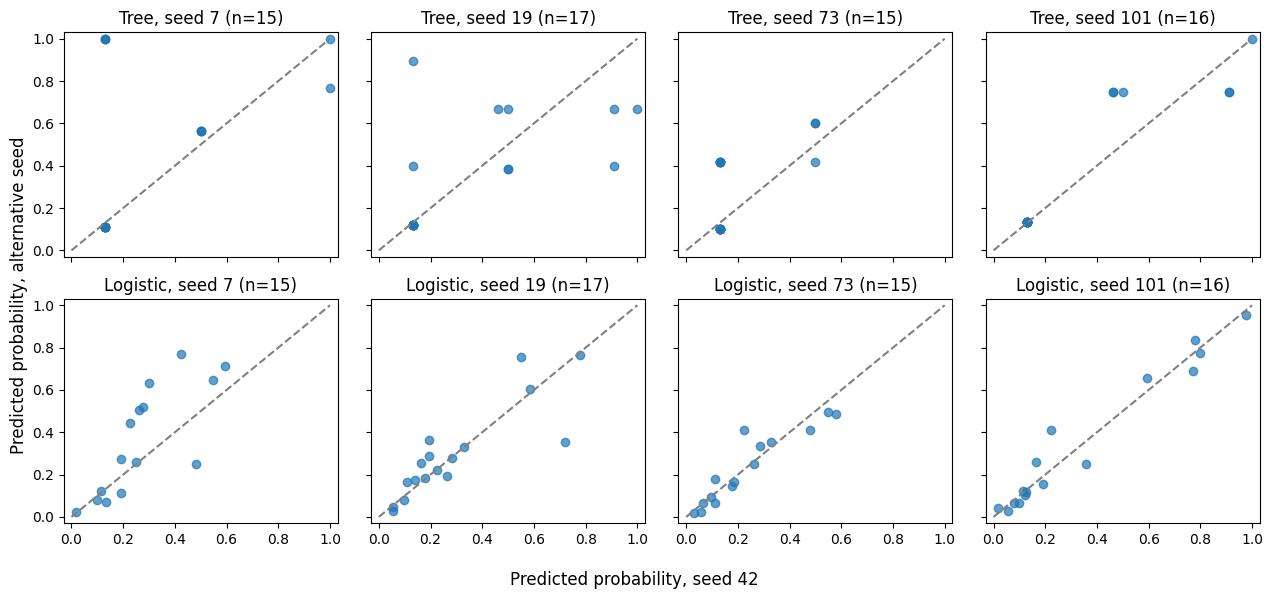

In [16]:
# q4a
paired = {}
fig, axes = plt.subplots(
    2, len(other_seeds), figsize=(13, 6), sharex=True, sharey=True
)

for row, name in enumerate(["Tree", "Logistic"]):
    for col, seed in enumerate(other_seeds):
        pair = pd.concat(
            [
                predictions_by_seed[baseline_seed][name].rename("baseline"),
                predictions_by_seed[seed][name].rename("alternative"),
            ],
            axis=1,
            join="inner",
        )
        paired[name, seed] = pair

        ax = axes[row, col]
        ax.scatter(pair["baseline"], pair["alternative"], alpha=0.7)
        ax.plot([0, 1], [0, 1], "--", color="gray")
        ax.set_title(f"{name}, seed {seed} (n={len(pair)})")
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)

fig.supxlabel(f"Predicted probability, seed {baseline_seed}")
fig.supylabel("Predicted probability, alternative seed")
fig.tight_layout()
plt.show()

In [17]:
# q4b
correlations = []

for (name, seed), pair in paired.items():
    correlations.append({
        "model": name,
        "seed": seed,
        "n": len(pair),
        "pearson_r": pair["baseline"].corr(pair["alternative"]),
    })

display(pd.DataFrame(correlations).round(3))

,model,seed,n,pearson_r
0,Tree,7,15,0.458
1,Tree,19,17,0.577
2,Tree,73,15,0.644
3,Tree,101,16,0.920
4,Logistic,7,15,0.781
5,Logistic,19,17,0.856
6,Logistic,73,15,0.926
7,Logistic,101,16,0.976


In [18]:
# q4c
agreement = []

for (name, seed), pair in paired.items():
    x_prob = pair[["baseline"]]
    y_prob = pair["alternative"]
    line = LinearRegression().fit(x_prob, y_prob)

    agreement.append({
        "model": name,
        "seed": seed,
        "intercept": line.intercept_,
        "slope": line.coef_[0],
        "r_squared": line.score(x_prob, y_prob),
        "mean_absolute_gap": (pair["baseline"] - y_prob).abs().mean(),
    })

display(pd.DataFrame(agreement).round(3))

,model,seed,intercept,slope,r_squared,mean_absolute_gap
0,Tree,7,0.301,0.569,0.210,0.211
1,Tree,19,0.183,0.486,0.333,0.166
2,Tree,73,0.123,0.833,0.415,0.129
3,Tree,101,0.054,0.946,0.846,0.075
4,Logistic,7,0.038,1.183,0.610,0.140
5,Logistic,19,0.060,0.826,0.733,0.070
6,Logistic,73,0.025,0.879,0.858,0.047
7,Logistic,101,0.013,0.972,0.952,0.051


### q5
**Regression Model**\
The regression models were generally more stable across splits. The mean probability gaps were about 5-15%. Some coefficients were consistent in direction such as <ejection_fraction> while others such as <smoking> were varied.

**Trees**\
The root feature stayed the same while later branches and thresholds changed. Agreement varied by seed with the mean probability gaps ranging from about 8-20%.
  

### q6
**False**\
Three of the four trees had 0.46-0.64 correlations with probabilty gaos of 13-21%. The 101 seed tree was an exception with a 0.92 correlation. Structural changes can leave similar predicitons, but in our case it only happened for one of the four trees.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 966be0e4a39d1d1ec537cc9ab76b2fca3225a316
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1.
Using this dataset, check out the data set heart_failure and appropriately clean it.

This is the code I have but make suggestions as you see fit and offer a revised version accordingly:

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')
df.columns = df.columns.str.strip().str.lower()

print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())

y = df['death_event'].astype(int)
X = df.drop(columns=['death_event', 'time'])
print(y.value_counts().sort_index())

2.
Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

Heres my existing code:

baseline_seed = 42
other_seeds = [7, 19, 73, 101]

def fit_split(seed):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)

    models = {
        "Tree": DecisionTreeClassifier(
            max_depth=3, min_samples_leaf=10, random_state=0
        ),
        "Logistic": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000)
        ),
    }

    predictions = pd.DataFrame(index=X_test.index)
    scores = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name] = model.predict_proba(X_test)[:, 1]

        scores.append({
            "seed": seed,
            "model": name,
            "accuracy": accuracy_score(y_test, model.predict(X_test)),
            "log_loss": log_loss(y_test, predictions[name]),
        })

    return models, predictions, scores

models, predictions, scores = fit_split(baseline_seed)
models_by_seed = {baseline_seed: models}
predictions_by_seed = {baseline_seed: predictions}
test_scores = scores.copy()

display(pd.DataFrame(scores).round(3))

3.
Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

this is my current code:

for seed in other_seeds:
    models, predictions, scores = fit_split(seed)
    models_by_seed[seed] = models
    predictions_by_seed[seed] = predictions
    test_scores.extend(scores)

display(pd.DataFrame(test_scores).round(3))

coefficients = {}

for seed, models in models_by_seed.items():
    print(f"Tree for seed {seed}")
    print(export_text(models["Tree"], feature_names=list(X.columns)))

    logistic = models["Logistic"]
    scaler = logistic.named_steps["standardscaler"]
    weights = logistic.named_steps["logisticregression"].coef_[0]
    coefficients[seed] = weights / scaler.scale_

coef_table = pd.DataFrame(coefficients, index=X.columns)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(coef_table)

4.
Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:

    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?

    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?

    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

paired = {}
fig, axes = plt.subplots(
    2, len(other_seeds), figsize=(13, 6), sharex=True, sharey=True
)

for row, name in enumerate(["Tree", "Logistic"]):
    for col, seed in enumerate(other_seeds):
        pair = pd.concat(
            [
                predictions_by_seed[baseline_seed][name].rename("baseline"),
                predictions_by_seed[seed][name].rename("alternative"),
            ],
            axis=1,
            join="inner",
        )
        paired[name, seed] = pair

        ax = axes[row, col]
        ax.scatter(pair["baseline"], pair["alternative"], alpha=0.7)
        ax.plot([0, 1], [0, 1], "--", color="gray")
        ax.set_title(f"{name}, seed {seed} (n={len(pair)})")
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)

fig.supxlabel(f"Predicted probability, seed {baseline_seed}")
fig.supylabel("Predicted probability, alternative seed")
fig.tight_layout()
plt.show()

correlations = []

for (name, seed), pair in paired.items():
    correlations.append({
        "model": name,
        "seed": seed,
        "n": len(pair),
        "pearson_r": pair["baseline"].corr(pair["alternative"]),
    })

display(pd.DataFrame(correlations).round(3))

agreement = []

for (name, seed), pair in paired.items():
    x_prob = pair[["baseline"]]
    y_prob = pair["alternative"]
    line = LinearRegression().fit(x_prob, y_prob)

    agreement.append({
        "model": name,
        "seed": seed,
        "intercept": line.intercept_,
        "slope": line.coef_[0],
        "r_squared": line.score(x_prob, y_prob),
        "mean_absolute_gap": (pair["baseline"] - y_prob).abs().mean(),
    })

display(pd.DataFrame(agreement).round(3))

respond by section


### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')
df.columns = df.columns.str.strip().str.lower()

binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'death_event']
skewed_cols = ['creatinine_phosphokinase', 'serum_creatinine', 'platelets']

# --- Integrity checks ---
print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())
assert df.isna().sum().sum() == 0
assert df.duplicated().sum() == 0
assert all(set(df[c].unique()) <= {0, 1} for c in binary_cols)

# --- Type fixes ---
df['age'] = df['age'].round().astype(int)              # 60.667 -> 61
df['platelets'] = df['platelets'].round().astype(int)
df[binary_cols] = df[binary_cols].astype('int8')

# --- Plausibility ranges (fail loudly, don't silently drop) ---
ranges = {
    'age': (0, 120),
    'ejection_fraction': (5, 90),
    'serum_sodium': (100, 160),
    'serum_creatinine': (0.1, 15),
    'creatinine_phosphokinase': (1, 20000),
    'platelets': (10_000, 1_000_000),
}
for col, (lo, hi) in ranges.items():
    assert df[col].between(lo, hi).all(), f'{col} out of range'

# --- Target / features (time dropped: follow-up duration leaks the outcome) ---
y = df['death_event']
X = df.drop(columns=['death_event', 'time'])
print(y.value_counts().sort_index())
print(f'Positive rate: {y.mean():.3f}')

# --- Stratified split BEFORE any scaling/transforms ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

2.
from sklearn.metrics import roc_auc_score, brier_score_loss

# in fit_split, return y_test too and add to the scores dict:
#   "roc_auc": roc_auc_score(y_test, predictions[name]),
#   "brier":   brier_score_loss(y_test, predictions[name]),
# return models, predictions, scores, y_test

models, predictions, scores, y_test = fit_split(baseline_seed)
models_by_seed = {baseline_seed: models}
predictions_by_seed = {baseline_seed: predictions}
y_test_by_seed = {baseline_seed: y_test}
test_scores = scores.copy()

for seed in other_seeds:
    m, p, s, yt = fit_split(seed)
    models_by_seed[seed] = m
    predictions_by_seed[seed] = p
    y_test_by_seed[seed] = yt
    test_scores += s

scores_df = pd.DataFrame(test_scores)
display(scores_df.round(3))
display(scores_df.groupby("model")[["accuracy", "log_loss", "roc_auc"]].agg(["mean", "std"]).round(3))

3.
import numpy as np  # CHANGE: needed for np.sign in the sign-flip check
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# CHANGE: added roc_auc_score and brier_score_loss; accuracy and log loss alone
# are noisy on 75 test rows, and a majority-class guess already gets ~0.68 accuracy
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, brier_score_loss

baseline_seed = 42
other_seeds = [7, 19, 73, 101]

def fit_split(seed):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=seed
    )

    models = {
        # CHANGE (optional): the tree's probabilities are overconfident (log loss up to 2.4);
        # try min_samples_leaf=15-20 or calibrate it to soften them
        "Tree": DecisionTreeClassifier(
            max_depth=3, min_samples_leaf=10, random_state=0
        ),
        "Logistic": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000)
        ),
    }

    predictions = pd.DataFrame(index=X_test.index)
    scores = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name] = model.predict_proba(X_test)[:, 1]

        scores.append({
            "seed": seed,
            "model": name,
            "accuracy": accuracy_score(y_test, model.predict(X_test)),
            "log_loss": log_loss(y_test, predictions[name]),
            # CHANGE: ROC AUC measures ranking quality and doesn't depend on a 0.5 cutoff
            "roc_auc": roc_auc_score(y_test, predictions[name]),
            # CHANGE: Brier score is less sensitive than log loss to the tree's 0/1 leaf probabilities
            "brier": brier_score_loss(y_test, predictions[name]),
        })

    # CHANGE: also return y_test, because each seed has a different test set and you
    # need the matching labels to evaluate the saved predictions later
    return models, predictions, scores, y_test

models, predictions, scores, y_test = fit_split(baseline_seed)  # CHANGE: unpack y_test
models_by_seed = {baseline_seed: models}
predictions_by_seed = {baseline_seed: predictions}
y_test_by_seed = {baseline_seed: y_test}  # CHANGE: store labels alongside predictions
test_scores = scores.copy()

for seed in other_seeds:
    models, predictions, scores, y_test = fit_split(seed)  # CHANGE: unpack y_test
    models_by_seed[seed] = models
    predictions_by_seed[seed] = predictions
    y_test_by_seed[seed] = y_test  # CHANGE: store labels for this seed
    test_scores.extend(scores)

scores_df = pd.DataFrame(test_scores)
display(scores_df.round(3))
# CHANGE: summarize mean and std per model across seeds, since a single split is noisy
display(scores_df.groupby("model")[["accuracy", "log_loss", "roc_auc"]].agg(["mean", "std"]).round(3))

coefficients = {}
std_coefs = {}          # CHANGE: standardized coefficients (per 1 SD), comparable across features
tree_importances = {}   # CHANGE: tree feature importances, to compare trees across seeds

for seed, models in models_by_seed.items():
    print(f"Tree for seed {seed}")
    print(export_text(models["Tree"], feature_names=list(X.columns)))

    logistic = models["Logistic"]
    scaler = logistic.named_steps["standardscaler"]
    weights = logistic.named_steps["logisticregression"].coef_[0]
    # Raw-unit coefficients (your original): good for clinical interpretation,
    # but not comparable across features with different scales
    coefficients[seed] = weights / scaler.scale_

    # CHANGE: the standardized coefficients are the raw `weights` before dividing by scale_
    std_coefs[seed] = weights
    tree_importances[seed] = models["Tree"].feature_importances_

coef_table = pd.DataFrame(coefficients, index=X.columns)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(coef_table)

# CHANGE: standardized coefficient table with mean, spread and sign-flip check across seeds
std_coef_table = pd.DataFrame(std_coefs, index=X.columns)
std_coef_table["mean"] = std_coef_table.mean(axis=1)
std_coef_table["std"] = std_coef_table.drop(columns="mean").std(axis=1)
std_coef_table["sign_flips"] = np.sign(std_coef_table[list(std_coefs)]).nunique(axis=1) > 1
display(std_coef_table.sort_values("mean", key=abs, ascending=False).round(2))

# CHANGE: tree importances per seed; features that appear for only 1-2 seeds are unstable
importance_table = pd.DataFrame(tree_importances, index=X.columns)
display(importance_table.round(2))

4.
# CHANGE: sensitivity check: score every seed's model on the same rows (all of X),
# so n is 299 instead of ~15. Rows in a model's training set are in-sample,
# so treat this as a supplement, not a replacement for the test-set comparison.
full_agreement = []
for name in ["Tree", "Logistic"]:
    base = models_by_seed[baseline_seed][name].predict_proba(X)[:, 1]
    for seed in other_seeds:
        alt = models_by_seed[seed][name].predict_proba(X)[:, 1]
        line = LinearRegression().fit(base.reshape(-1, 1), alt)
        full_agreement.append({
            "model": name, "seed": seed,
            "pearson_r": np.corrcoef(base, alt)[0, 1],
            "intercept": line.intercept_, "slope": line.coef_[0],
            "r_squared": line.score(base.reshape(-1, 1), alt),
            "mean_absolute_gap": np.abs(base - alt).mean(),
        })
display(pd.DataFrame(full_agreement).round(3))

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | reject | The AI suggestions didn't really add much but made the code much longer than what already existed. For that reason, we decided to just reject its suggestions. |
| 2 | reject | Once again, the AI suggestions weren't necessary. Specifically, it wanted to incoporate multiple seeds for additional variety which did not seem to add much value. For this reason, we decided to reject the suggestions. |
| 3 | modify | The AI suggested some good ideas such as adjusting trees values and altering the standardized coefficient table which improve the viability of the code. However, some of the other suggestions didn't really make a difference compared to our code so we felt it was fair to leave those parts out.
| 4 | accept | The AI provided good ideas on how to better verify the solutions our code came up with via a sensitivity check. Didn't completely change the function of our code, but it added a supplemental feature for verifying the solutions.


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')
df.columns = df.columns.str.strip().str.lower()

print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())

y = df['death_event'].astype(int)
X = df.drop(columns=['death_event', 'time'])
print(y.value_counts().sort_index())

baseline_seed = 42
other_seeds = [7, 19, 73, 101]

def fit_split(seed):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)

    models = {
        "Tree": DecisionTreeClassifier(
            max_depth=3, min_samples_leaf=10, random_state=0
        ),
        "Logistic": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000)
        ),
    }

    predictions = pd.DataFrame(index=X_test.index)
    scores = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name] = model.predict_proba(X_test)[:, 1]

        scores.append({
            "seed": seed,
            "model": name,
            "accuracy": accuracy_score(y_test, model.predict(X_test)),
            "log_loss": log_loss(y_test, predictions[name]),
        })

    return models, predictions, scores

models, predictions, scores = fit_split(baseline_seed)
models_by_seed = {baseline_seed: models}
predictions_by_seed = {baseline_seed: predictions}
test_scores = scores.copy()

display(pd.DataFrame(scores).round(3))

for seed in other_seeds:
    models, predictions, scores = fit_split(seed)
    models_by_seed[seed] = models
    predictions_by_seed[seed] = predictions
    test_scores.extend(scores)

display(pd.DataFrame(test_scores).round(3))

coefficients = {}

for seed, models in models_by_seed.items():
    print(f"Tree for seed {seed}")
    print(export_text(models["Tree"], feature_names=list(X.columns)))

    logistic = models["Logistic"]
    scaler = logistic.named_steps["standardscaler"]
    weights = logistic.named_steps["logisticregression"].coef_[0]
    coefficients[seed] = weights / scaler.scale_

coef_table = pd.DataFrame(coefficients, index=X.columns)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(coef_table)

paired = {}
fig, axes = plt.subplots(
    2, len(other_seeds), figsize=(13, 6), sharex=True, sharey=True
)

for row, name in enumerate(["Tree", "Logistic"]):
    for col, seed in enumerate(other_seeds):
        pair = pd.concat(
            [
                predictions_by_seed[baseline_seed][name].rename("baseline"),
                predictions_by_seed[seed][name].rename("alternative"),
            ],
            axis=1,
            join="inner",
        )
        paired[name, seed] = pair

        ax = axes[row, col]
        ax.scatter(pair["baseline"], pair["alternative"], alpha=0.7)
        ax.plot([0, 1], [0, 1], "--", color="gray")
        ax.set_title(f"{name}, seed {seed} (n={len(pair)})")
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)

fig.supxlabel(f"Predicted probability, seed {baseline_seed}")
fig.supylabel("Predicted probability, alternative seed")
fig.tight_layout()
plt.show()

correlations = []

for (name, seed), pair in paired.items():
    correlations.append({
        "model": name,
        "seed": seed,
        "n": len(pair),
        "pearson_r": pair["baseline"].corr(pair["alternative"]),
    })

display(pd.DataFrame(correlations).round(3))

agreement = []

for (name, seed), pair in paired.items():
    x_prob = pair[["baseline"]]
    y_prob = pair["alternative"]
    line = LinearRegression().fit(x_prob, y_prob)

    agreement.append({
        "model": name,
        "seed": seed,
        "intercept": line.intercept_,
        "slope": line.coef_[0],
        "r_squared": line.score(x_prob, y_prob),
        "mean_absolute_gap": (pair["baseline"] - y_prob).abs().mean(),
    })

display(pd.DataFrame(agreement).round(3))

#Questions 5 and 6 answered above.

### *Reflection on AI assistance
In your own words without generative AI.

Generally, the AI was not overly helpful in identifying new components of code to assist what we already had. This resulted in us rejecting a few of the suggestions for the first few questions. However, it did provide some useful feedback in later questions such as altering the implementation of different seeds which allowed us to better diversify our analysis and account for different views of the data more generally. Additionally, it did provide helpful suggestions in the sensitivity check because it provided another dimension of analysis to confirm the reasonableness of our answers. Overall, the AI didn't contribute too much new information that benefitted our code, but that could be due to the fact that we did a good job to begin with. We do wish that the AI could have pointed out alternative ways to complete the code which could have also led to new ideas of how to solve the problems in the lab but that limitation is subtle and not important when looking more holistically at its impact.